In [1]:
# Registro de ejecucion: fecha, fuentes, licencias y versiones de los modelos
# (lo exige el enunciado como primera celda)
import datetime, platform
from importlib.metadata import version, PackageNotFoundError

import pandas as pd

print("Fecha de ejecucion:", datetime.datetime.now().isoformat(timespec="seconds"))
print("Python:", platform.python_version(), "·", platform.system(), platform.release())
for paquete in ["paddleocr", "faster-whisper", "torch", "pandas", "plotly"]:
    try:
        print(f"{paquete}: {version(paquete)}")
    except PackageNotFoundError:
        print(f"{paquete}: no instalado")

pd.read_csv("datos/fuentes.csv")

Fecha de ejecucion: 2026-10-25T19:56:13
Python: 3.12.15 · Windows 11
paddleocr: 3.7.0
faster-whisper: 1.2.1
torch: 2.13.0
pandas: 2.3.3
plotly: 7.0.0


,id,modalidad,fuente_url,licencia,acceso
0,doc_bcrp_1922,documento,https://www.bcrp.gob.pe/docs/Publicaciones/Mem...,BCRP: reproduccion permitida citando la fuente...,Descarga directa PDF. Escaneo puro sin capa de...
1,doc_bcrp_1923,documento,https://www.bcrp.gob.pe/docs/Publicaciones/Mem...,BCRP: reproduccion permitida citando la fuente,Descarga directa PDF. Escaneo puro sin capa de...
2,doc_bcrp_1924,documento,https://www.bcrp.gob.pe/docs/Publicaciones/Mem...,BCRP: reproduccion permitida citando la fuente,Descarga directa PDF. Escaneo con capa OCR previa
3,doc_bcrp_1925,documento,https://www.bcrp.gob.pe/docs/Publicaciones/Mem...,BCRP: reproduccion permitida citando la fuente,Descarga directa PDF. Escaneo con capa OCR previa
4,doc_bcrp_1926,documento,https://www.bcrp.gob.pe/docs/Publicaciones/Mem...,BCRP: reproduccion permitida citando la fuente,Descarga directa PDF. Escaneo con capa OCR previa
5,doc_bcrp_1927,documento,https://www.bcrp.gob.pe/docs/Publicaciones/Mem...,BCRP: reproduccion permitida citando la fuente,Descarga directa PDF. Escaneo con capa OCR previa
6,doc_bcrp_1928,documento,https://www.bcrp.gob.pe/docs/Publicaciones/Mem...,BCRP: reproduccion permitida citando la fuente,Descarga directa PDF. Escaneo con capa OCR previa
7,doc_bcrp_1929,documento,https://www.bcrp.gob.pe/docs/Publicaciones/Mem...,BCRP: reproduccion permitida citando la fuente,Descarga directa PDF. Escaneo con capa OCR previa
8,doc_bcrp_condiciones,referencia,https://estadisticas.bcrp.gob.pe/estadisticas/...,Pagina de condiciones de uso del BCRP,Consultada para sustentar la licencia de las M...
9,man_guaman_poma,documento,https://poma.kb.dk/permalink/2006/poma/info/en...,Creative Commons Public Domain Mark 1.0 (Det K...,Visor en linea del manuscrito GKS 2232 4o de 1615


# Archivos económicos del Perú: ¿se pueden buscar?

**Notebook 01 — Extracción: OCR, transcripción, limpieza y EDA**

## Decisiones sobre el corpus de documentos

### Decision 1: 8 paginas impresas, elegidas por dificultad

Los tres PDF impresos dan 54 paginas (`extraer_paginas.py`, 300 ppp), todas escaneo puro,
sin capa de texto. El minimo del enunciado es 8 impresos, dentro de 25 documentos en total.
Se usan **8 paginas**, elegidas **antes de correr el OCR** para que varien en dificultad:
portada, texto corrido y una pagina con tablas de cifras.

| PDF | Pagina | Contenido | Por que entra |
|---|---|---|---|
| Carta a Gamarra, Cuzco 1832 | p001 | portada | tipografia decorativa, papel amarillento |
| Carta a Gamarra, Cuzco 1832 | p003 | inicio de la carta | texto corrido denso, tipografia antigua |
| Carta a Gamarra, Cuzco 1832 | p023 | Notas | la pagina mas manchada; el folleto no tiene tablas |
| Memoria BCRP 1922 | p001 | portada y directorio | cifras de capital y nombres propios |
| Memoria BCRP 1922 | p002 | texto corrido | montos en libras peruanas dentro del texto |
| Memoria BCRP 1922 | p005 | balance al 31-12-1922 | tabla de cifras en letra pequena |
| Memoria BCRP 1923 | p003 | texto corrido | montos dentro del texto, escaneo gris |
| Memoria BCRP 1923 | p014 | Cuadro N.º 3 | tabla densa de cifras mensuales |

**Paginas descartadas (46)**, movidas a `datos/raw/documentos/paginas/_descartadas/`.
No son ilegibles: quedan fuera para ajustar el corpus al minimo y mantener el OCR manejable en CPU.

- Carta a Gamarra: p002, p004–p022, p024, p025 (22 paginas)
- Memoria BCRP 1922: p003, p004, p006, p007 (4 paginas)
- Memoria BCRP 1923: p001, p002, p004–p013, p015–p022 (20 paginas)

Las Memorias de 1924 a 1929 no entran como impresos: traen capa de texto (corrompida) y se usan
solo como hallazgo de partida.

### Decision 2: la foto de la boleta se usa sin tapar nada

`Foto_boletas.jpeg` se reviso a mano antes de incluirla. No contiene datos de una persona real:

- Cliente: "CLIENTE EVENTUAL", con DNI `00000001` (valor generico de boleta sin cliente identificado).
- RUC, direccion y telefono pertenecen a la empresa emisora, no a una persona natural.
- "Vendedor TULLUMAYO1" es un codigo de caja, no un nombre.

Si alguna foto nueva trae un nombre o DNI real, se tapa en la imagen antes de incluirla:
seudonimizar solo el texto del OCR no basta si la imagen se publica.

## Decisiones sobre el corpus de audio

### Decision 3: 400 clips de OpenSLR 73 como corpus de espanol peruano

`datos_audio.py` baja 400 clips (200 de mujeres y 200 de hombres, semilla 2026) del corpus
OpenSLR 73 (CC BY-SA 4.0). `transcribir_audio.py` los transcribe con la **linea base del
enunciado: faster-whisper `small` en CPU, con VAD siempre activado**. Resultado: 400 clips,
42,0 minutos de audio, ningun clip sin texto y ningun error. El tiempo de computo de cada clip
queda en `datos/asr_tiempos.csv` (RTF global 0,373) para la Parte 2.

Cada clip de OpenSLR 73 tiene una sola voz, por eso `n_hablantes = 1`.

### Decision 4: entrevista de Espika FM para la diarizacion (2 hablantes)

Fuente: Espika FM 90.7 (Uruguay), *Al mundo le falta un tornillo*, 21/11/2020, bloque 4
(CC BY-SA 4.0, registrada en `fuentes.csv` como `aud_espika_20201121`). Es una entrevista
sobre la crisis politica del Peru de noviembre de 2020.

**Advertencia: el conductor no es peruano.** Es uruguayo. Solo el entrevistado habla espanol
peruano. Por eso este audio **no se suma a los minutos de espanol peruano**: sirve para medir
la diarizacion y el comportamiento del ASR en una conversacion real (telefono, voces
superpuestas, cortes de linea), no el acento.

Del mp3 (27:53) se cortan dos tramos con `transcribir_entrevista.py`. Los cortes se eligieron
con un mapa de VAD y energia cada 15 s, antes de ver las transcripciones:

| id | Tramo del mp3 | Duracion | Contenido | n_hablantes |
|---|---|---|---|---|
| `aud_espika_20201121_conversacion` | 07:00 a 13:00 | 6 min | conversacion entre conductor y entrevistado | 2 |
| `aud_espika_20201121_musica` | 23:15 a 25:15 | 2 min | cierre de la entrevista y comienzo de la cancion "A La Molina" (Hermanos Santa Cruz) | 2 |

**El tramo con musica se incluye a proposito como caso dificil.** Sirve para ver si el VAD
descarta la musica o si Whisper "alucina" letra o texto inventado.

Como se proceso:

- ASR: faster-whisper `small` en CPU con VAD, igual que la linea base.
- Diarizacion: `voz.diarizar` (huellas de voz WeSpeaker y agrupamiento por similitud), con
  2 hablantes. Sin fijar el numero, el agrupamiento automatico tambien estimo 2 en ambos tramos.
- Roles: `diarizar` numera por orden de aparicion. Los dos tramos empiezan con el entrevistado
  hablando, asi que H1 = entrevistado y H2 = conductor. Se verifico leyendo el texto: H2 es
  quien hace las preguntas.
- Seudonimizacion: el entrevistado aparece como `ENTREVISTADO (Peru)` y su nombre se cambia por
  `[ENTREVISTADO]` en el texto. Los nombres de politicos (personas publicas) se mantienen.
- Exportacion: `datos/entrevistas/<id>.csv` (segmentos con tiempos y hablante), `.srt` y `.txt`.
  En `transcripciones.csv`, la columna `texto_asr` va sin marcas de hablante, para el WER.

Primeras observaciones (sin referencia manual todavia, asi que no hay WER):

- Tramo con musica: el ultimo segmento con texto termina en el segundo 36 de 120. **La cancion
  no genero texto**: el VAD la descarto y no hubo alucinaciones. En cambio, el cierre hablado
  mezcla las dos voces en un solo hablante (5 de 6 segmentos van al conductor). Son pocos
  segmentos y largos, y la diarizacion por segmento no puede separar dos voces dentro de uno.
- Tramo de conversacion: 227 segmentos, 117 de menos de 1 s. Los turnos cortos ("Se cortó ahí",
  "Ahora sí") quedan bien separados. Hay errores de nombres propios y siglas
  ("discarra" por Vizcarra, "zunera" por SUNEDU).
- Tiempo de computo: RTF 0,38 en la conversacion (similar a los clips) y 0,09 en el tramo con
  musica, porque el VAD descarta la cancion antes de transcribir.

Los archivos de audio (`datos/raw/`) no se versionan. La cancion tiene derechos de terceros
sin licencia declarada: el dashboard no debe reproducir el tramo musical.

In [2]:
# Resultados de la entrevista (generados por transcribir_entrevista.py)
from pathlib import Path

for ident in ["aud_espika_20201121_conversacion", "aud_espika_20201121_musica"]:
    seg = pd.read_csv(Path("datos/entrevistas") / f"{ident}.csv")
    seg["duracion"] = seg["fin"] - seg["inicio"]
    print(f"\n{ident}: {len(seg)} segmentos, ultimo termina en {seg['fin'].max():.1f} s")
    display(seg.groupby("hablante")["duracion"].agg(["count", "sum"]).round(1))
    print((Path("datos/entrevistas") / f"{ident}.txt").read_text(encoding="utf-8")[:800])


aud_espika_20201121_conversacion: 227 segmentos, ultimo termina en 359.7 s


,count,sum
hablante,,
CONDUCTOR (Uruguay),38,67.3
ENTREVISTADO (Peru),189,268.6


[00:00:00] ENTREVISTADO (Peru): en el tema de los parámetros que se anunciaron en la trayectra en las protestas. Lo que pasa es que en todo este digamos, en toda esta coyuntura de policía política, se han disibilizado una serie de intereses, intereses por todo de grupos que tienen representación parlamentaria, pero que han hecho de la educación superior, especialmente de la educación universitaria, un negocio que tiene fuerzas políticas que tienen mantener el negocio puntuable y una de las cosas que pudieron haber que hagan mejor la superinteligencia nacional de educación superior que la que superviza la zunera y la que superviza la educación superior aquí en el interior. Esa es una parte de los intereses, otros intereses que no tienen.

[00:00:51] CONDUCTOR (Uruguay): O sea que está vincu

aud_espika_20201121_musica: 6 segmentos, ultimo termina en 36.2 s


,count,sum
hablante,,
CONDUCTOR (Uruguay),5,26.4
ENTREVISTADO (Peru),1,9.8


[00:00:00] ENTREVISTADO (Peru): todo los instrumentos de viento y no ritmo. Hay una serie de últimamente un arqueólogo musical

[00:00:09] CONDUCTOR (Uruguay): de la Amazonía, pero también tiene su color rostro. Sin duda. La cumbia feropeiruana. Sin duda, sin duda. Bueno, gracias [ENTREVISTADO], por todo. Bueno, además nos agregó el musical. Vamos a tener que hacer un programa y una entrevista sobre música. Es impresionante [ENTREVISTADO], toda la información que nos ha dejado. Es fuerte abrazo y bueno, nos vamos disfrutando de los hermanos Santa Cruz a la Molina.

## Datos de entrada

El OCR ya se corrio con `ocr_documentos.py` y la transcripcion con `transcribir_audio.py` y
`transcribir_entrevista.py`. Aqui se leen sus salidas: `documentos.csv` (un texto por documento),
`ocr_lineas.csv` (una fila por linea detectada, con su confianza) y `transcripciones.csv`.

Todo se lee como texto (`dtype=str`) para que la exportacion final no cambie formatos que no tocamos.

In [3]:
import hashlib
import re

import numpy as np
import plotly.express as px
import plotly.io as pio

# GitHub no muestra los graficos interactivos: si hay kaleido, se guarda tambien una imagen PNG
try:
    import kaleido  # noqa: F401
    pio.renderers.default = "plotly_mimetype+png"
    pio.renderers["png"].width, pio.renderers["png"].height = 900, 520
except ImportError:
    pio.renderers.default = "plotly_mimetype"

# un color fijo por tipo, igual en todos los graficos
COLORES = {"impreso": "#4C78A8", "foto": "#F58518", "manuscrito": "#54A24B"}

COLUMNAS_DOC = ["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia"]
COLUMNAS_AUD = ["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr",
                "n_hablantes", "texto_referencia"]

docs = pd.read_csv("datos/documentos.csv", dtype=str, keep_default_na=False)
lineas = pd.read_csv("datos/ocr_lineas.csv", dtype={"texto": str}, keep_default_na=False)
trans = pd.read_csv("datos/transcripciones.csv", dtype=str, keep_default_na=False)
trans["segundos"] = trans["duracion_seg"].astype(float)

print(f"{len(docs)} documentos, {len(lineas)} lineas de OCR, {len(trans)} audios "
      f"({trans['segundos'].sum() / 60:.1f} min)")
docs["tipo"].value_counts()

28 documentos, 1376 lineas de OCR, 402 audios (50.0 min)


tipo
foto          10
manuscrito    10
impreso        8
Name: count, dtype: int64

## Seudonimizacion

**Documentos.** Se buscan en el texto del OCR cuatro tipos de dato personal con expresiones
regulares: DNI, celular (9 digitos que empiezan en 9), correo y RUC de persona natural
(empieza en 10; el RUC que empieza en 20 es de una empresa). Cada hallazgo se revisa a mano:

- si es de una persona, se reemplaza por una marca (`[DNI]`, `[CELULAR]`, ...);
- si no lo es, se deja y **se anota por que** en `NO_PERSONALES`.

Una expresion regular no reconoce nombres de personas: por eso los textos tambien se leyeron
(Decision 2). Los nombres que aparecen son de personajes historicos o publicos (Agustin Gamarra,
directores del BCRP de 1922) y se mantienen.

**Audio.** La entrevista se seudonimizo al transcribirla (`transcribir_entrevista.py`): el nombre
del entrevistado se cambio por `[ENTREVISTADO]` y los hablantes por su rol. Aqui solo se verifica.
El nombre real no se escribe en este notebook a proposito. Los clips de OpenSLR 73 ya vienen con
codigos de hablante (`pef_01523`) y son frases leidas, sin datos personales.

In [4]:
DETECTORES = {
    "DNI": r"\bDNI\s*[:.]?\s*(\d{8})(?!\d)",
    "CELULAR": r"(?<!\d)(9\d{8})(?!\d)",
    "CORREO": r"([\w.+-]+@[\w-]+\.[\w.]+)",
    "RUC_PERSONA": r"(?<!\d)(10\d{9})(?!\d)",
}
# revisados a mano: aparecen en el corpus pero no son datos de una persona
NO_PERSONALES = {
    "00000001": "DNI generico de 'CLIENTE EVENTUAL' en la boleta (Decision 2)",
    "915372786": "telefono de la empresa emisora de la boleta (RUC 20..., persona juridica)",
}


def hallazgos(ident, texto):
    for dato, patron in DETECTORES.items():
        for m in re.finditer(patron, texto):
            valor = m.group(1)
            accion = f"se mantiene: {NO_PERSONALES[valor]}" if valor in NO_PERSONALES else f"-> [{dato}]"
            yield {"id": ident, "dato": dato, "valor": valor, "accion": accion}


def seudonimizar(texto):
    for dato, patron in DETECTORES.items():
        texto = re.sub(patron, lambda m: m.group(0) if m.group(1) in NO_PERSONALES
                       else m.group(0).replace(m.group(1), f"[{dato}]"), texto)
    return texto


revision = pd.DataFrame(
    [h for i, t in zip(docs["id"], docs["texto_ocr"]) for h in hallazgos(i, t)]
    + [h for i, t in zip(trans["id"], trans["texto_asr"]) for h in hallazgos(i, t)],
    columns=["id", "dato", "valor", "accion"])

antes_doc, antes_lin, antes_aud = docs["texto_ocr"].copy(), lineas["texto"].copy(), trans["texto_asr"].copy()
docs["texto_ocr"] = docs["texto_ocr"].map(seudonimizar)
lineas["texto"] = lineas["texto"].map(seudonimizar)
trans["texto_asr"] = trans["texto_asr"].map(seudonimizar)
print("Textos cambiados: documentos", (docs["texto_ocr"] != antes_doc).sum(),
      "| lineas de OCR", (lineas["texto"] != antes_lin).sum(),
      "| audios", (trans["texto_asr"] != antes_aud).sum())
revision

Textos cambiados: documentos 0 | lineas de OCR 0 | audios 0


,id,dato,valor,accion
0,fot_Foto_boletas,DNI,00000001,se mantiene: DNI generico de 'CLIENTE EVENTUAL...
1,fot_Foto_boletas,CELULAR,915372786,se mantiene: telefono de la empresa emisora de...


In [5]:
# verificacion de la entrevista: rol en vez de nombre, en el CSV y en los segmentos exportados
for ident in ["aud_espika_20201121_conversacion", "aud_espika_20201121_musica"]:
    texto = trans.loc[trans["id"] == ident, "texto_asr"].iloc[0]
    seg = pd.read_csv(Path("datos/entrevistas") / f"{ident}.csv")
    print(f"{ident}: '[ENTREVISTADO]' aparece {texto.count('[ENTREVISTADO]')} veces; "
          f"hablantes = {sorted(seg['hablante'].unique())}")

aud_espika_20201121_conversacion: '[ENTREVISTADO]' aparece 0 veces; hablantes = ['CONDUCTOR (Uruguay)', 'ENTREVISTADO (Peru)']
aud_espika_20201121_musica: '[ENTREVISTADO]' aparece 2 veces; hablantes = ['CONDUCTOR (Uruguay)', 'ENTREVISTADO (Peru)']


## Duplicados por hash y reporte de descartes

Dos archivos son el mismo si tienen el mismo **hash SHA-256** de sus bytes, aunque tengan nombres
distintos. Se calcula el hash de cada imagen y cada audio de `datos/raw/` (no se versiona, por eso
esta celda solo corre en la maquina local). De cada grupo de iguales se queda el primero por nombre.

Ademas se descarta:

- un documento **ilegible**: el OCR no detecta ninguna linea;
- un audio **sin voz**: el ASR, con VAD, no devuelve texto.

Una confianza baja **no** es motivo de descarte: las paginas dificiles se eligieron a proposito
(Decision 1) y son justo las que hay que medir en la Parte 2.

Las 46 paginas que quedaron fuera por seleccion (Decision 1) tambien entran al reporte, para que
todo descarte quede registrado en `datos/descartes.csv`.

In [6]:
RAW = Path("datos/raw")
assert RAW.is_dir(), "datos/raw no esta: esta celda necesita los archivos originales (no se versionan)"


def sha256(ruta, bloque=1 << 20):
    h = hashlib.sha256()
    with ruta.open("rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()


carpetas = {RAW / "documentos/paginas": "documento", RAW / "documentos/fotos": "documento",
            RAW / "documentos/manuscritos": "documento", RAW / "audio/es_peru": "audio",
            RAW / "audio/entrevistas/tramos": "audio"}
EXT = {".jpg", ".jpeg", ".png", ".wav"}
hashes = pd.DataFrame(
    [{"archivo": p.name, "modalidad": mod, "sha256": sha256(p)}
     for carpeta, mod in carpetas.items()
     for p in sorted(carpeta.iterdir()) if p.suffix.lower() in EXT])
hashes["duplicado"] = hashes.duplicated("sha256", keep="first")
print(f"{len(hashes)} archivos con hash: {hashes['sha256'].nunique()} distintos, "
      f"{hashes['duplicado'].sum()} duplicados")
print(hashes["modalidad"].value_counts().to_string())

# los textos iguales NO son archivos duplicados: en OpenSLR 73 varias personas leen la misma frase
clips = trans[trans["id"].str.startswith("aud_pe")]
print(f"\nClips con un texto ASR repetido: {clips['texto_asr'].duplicated(keep=False).sum()} "
      f"de {len(clips)} (misma frase, distinta voz: se quedan todos)")

430 archivos con hash: 430 distintos, 0 duplicados
modalidad
audio        402
documento     28

Clips con un texto ASR repetido: 47 de 400 (misma frase, distinta voz: se quedan todos)


In [7]:
n_lineas = lineas.groupby("archivo").size()
sin_lineas = docs.loc[~docs["archivo"].isin(n_lineas.index) | (docs["texto_ocr"].str.strip() == ""), "archivo"]
sin_voz = trans.loc[trans["texto_asr"].str.strip() == "", "archivo_audio"]
seleccion = sorted(p.name for p in (RAW / "documentos/paginas/_descartadas").glob("*.jpg"))

descartes = pd.concat([
    hashes.loc[hashes["duplicado"], ["archivo", "modalidad"]].assign(motivo="duplicado por hash SHA-256"),
    pd.DataFrame({"archivo": sin_lineas, "modalidad": "documento", "motivo": "ilegible: OCR sin lineas"}),
    pd.DataFrame({"archivo": sin_voz, "modalidad": "audio", "motivo": "sin voz: ASR sin texto"}),
    pd.DataFrame({"archivo": seleccion, "modalidad": "documento",
                  "motivo": "fuera de la seleccion de 8 impresos (Decision 1), no por ilegible"}),
], ignore_index=True)
descartes.to_csv("datos/descartes.csv", index=False, encoding="utf-8")

# se quitan del corpus los duplicados, ilegibles y sin voz (las 46 paginas ya no estaban)
fuera = set(descartes["archivo"])
docs = docs[~docs["archivo"].isin(fuera)]
lineas = lineas[~lineas["archivo"].isin(fuera)]
trans = trans[~trans["archivo_audio"].isin(fuera)]

print(descartes["motivo"].value_counts().to_string())
descartes.groupby("motivo").head(3)

motivo
fuera de la seleccion de 8 impresos (Decision 1), no por ilegible    46


,archivo,modalidad,motivo
0,Manuscrito-31_PE_1352-Carta_escrita_a_Don_Agus...,documento,fuera de la seleccion de 8 impresos (Decision ...
1,Manuscrito-31_PE_1352-Carta_escrita_a_Don_Agus...,documento,fuera de la seleccion de 8 impresos (Decision ...
2,Manuscrito-31_PE_1352-Carta_escrita_a_Don_Agus...,documento,fuera de la seleccion de 8 impresos (Decision ...


In [8]:
# minimos del enunciado despues de la limpieza
clips = trans[trans["id"].str.startswith("aud_pe")]
minimos = pd.DataFrame([
    ("Documentos impresos", 8, (docs["tipo"] == "impreso").sum()),
    ("Fotos con sombra o inclinacion", 8, (docs["tipo"] == "foto").sum()),
    ("Manuscritos", 9, (docs["tipo"] == "manuscrito").sum()),
    ("Documentos en total", 25, len(docs)),
    ("Clips de espanol peruano", 20, len(clips)),
    ("Minutos de espanol peruano", 30, round(clips["segundos"].sum() / 60, 1)),
    ("Audios con 2+ hablantes", 1, (trans["n_hablantes"].astype(int) >= 2).sum()),
], columns=["requisito", "minimo", "actual"])
minimos["cumple"] = np.where(minimos["actual"] >= minimos["minimo"], "si", "NO")
minimos

,requisito,minimo,actual,cumple
0,Documentos impresos,8,8.0,si
1,Fotos con sombra o inclinacion,8,10.0,si
2,Manuscritos,9,10.0,si
3,Documentos en total,25,28.0,si
4,Clips de espanol peruano,20,400.0,si
5,Minutos de espanol peruano,30,42.0,si
6,Audios con 2+ hablantes,1,2.0,si


## Exploracion: donde duda el OCR

PaddleOCR da una **confianza** entre 0 y 1 para cada linea que lee. Se llama **linea dudosa** a la
que tiene confianza menor que 0,90 (el mismo corte que usa `ocr_documentos.py`).

Ojo: la confianza es lo que el modelo *cree* de si mismo, no el error real. El error real (CER)
solo se puede medir contra la transcripcion manual de la Parte 2.

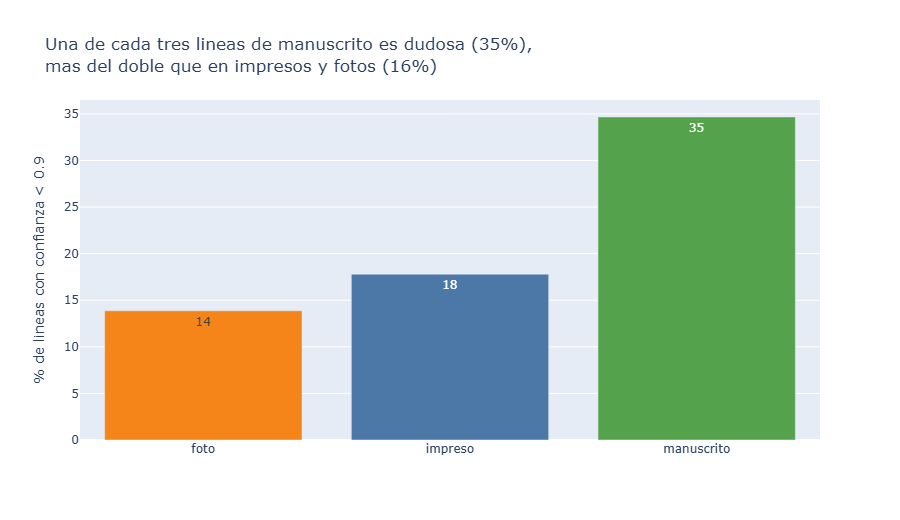

,tipo,lineas,dudosas,mediana,pct_dudosas
0,foto,548,76,0.995,13.869
1,impreso,427,76,0.994,17.799
2,manuscrito,401,139,0.938,34.663


In [9]:
UMBRAL = 0.90
lineas["dudosa"] = lineas["confianza"] < UMBRAL
por_tipo = (lineas.groupby("tipo")
            .agg(lineas=("linea", "size"), dudosas=("dudosa", "sum"), mediana=("confianza", "median"))
            .reset_index())
por_tipo["pct_dudosas"] = 100 * por_tipo["dudosas"] / por_tipo["lineas"]
man = por_tipo.set_index("tipo").loc["manuscrito"]
resto = por_tipo[por_tipo["tipo"] != "manuscrito"]
pct_resto = 100 * resto["dudosas"].sum() / resto["lineas"].sum()

fig = px.bar(por_tipo.sort_values("pct_dudosas"), x="tipo", y="pct_dudosas", color="tipo", color_discrete_map=COLORES,
             text_auto=".0f", hover_data=["lineas", "dudosas", "mediana"],
             labels={"pct_dudosas": f"% de lineas con confianza < {UMBRAL}", "tipo": ""},
             title=(f"Una de cada tres lineas de manuscrito es dudosa ({man['pct_dudosas']:.0f}%), "
                    f"<br>mas del doble que en impresos y fotos ({pct_resto:.0f}%)"))
fig.update_layout(showlegend=False)
fig.show()
por_tipo.round(3)

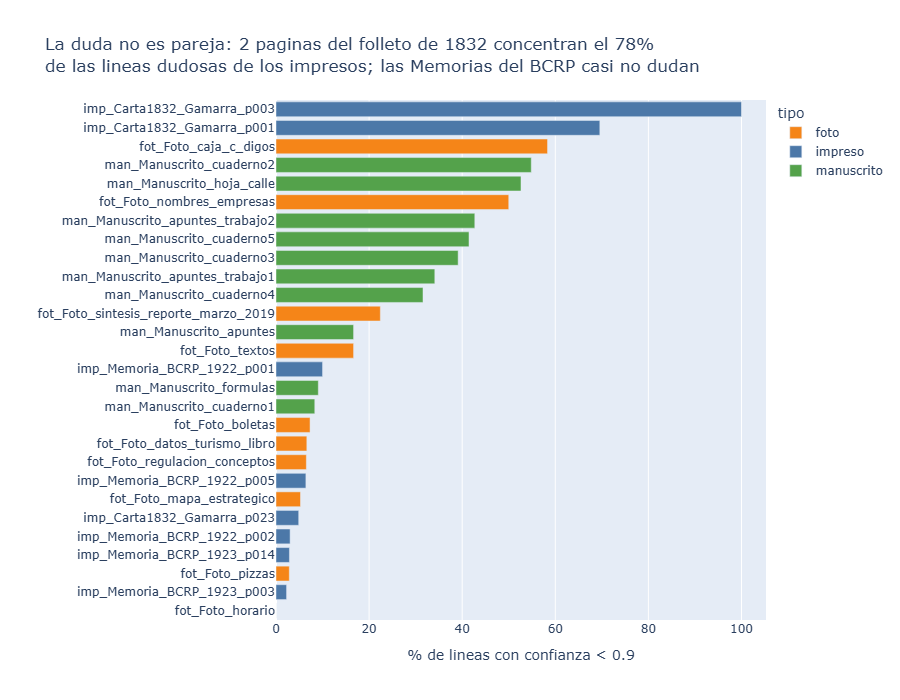

,documento,lineas,dudosas,confianza_media
11,imp_Carta1832_Gamarra_p003,43,43,0.555
10,imp_Carta1832_Gamarra_p001,23,16,0.649


In [10]:
por_doc = (lineas.groupby(["id", "tipo"])
           .agg(lineas=("linea", "size"), dudosas=("dudosa", "sum"), confianza_media=("confianza", "mean"))
           .reset_index())
por_doc["pct_dudosas"] = 100 * por_doc["dudosas"] / por_doc["lineas"]
por_doc["documento"] = por_doc["id"].str.replace("_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n", "_Carta1832")

imp = por_doc[por_doc["tipo"] == "impreso"].sort_values("dudosas", ascending=False)
peores = imp.head(2)
pct_peores = 100 * peores["dudosas"].sum() / imp["dudosas"].sum()

fig = px.bar(por_doc.sort_values("pct_dudosas"), x="pct_dudosas", y="documento", color="tipo", color_discrete_map=COLORES,
             orientation="h", hover_data=["lineas", "dudosas", "confianza_media"],
             labels={"pct_dudosas": f"% de lineas con confianza < {UMBRAL}", "documento": ""},
             title=(f"La duda no es pareja: 2 paginas del folleto de 1832 concentran el {pct_peores:.0f}% "
                    f"<br>de las lineas dudosas de los impresos; las Memorias del BCRP casi no dudan"))
fig.update_layout(height=700, yaxis={"categoryorder": "total ascending"})
fig.show(height=700)
peores[["documento", "lineas", "dudosas", "confianza_media"]].round(3)

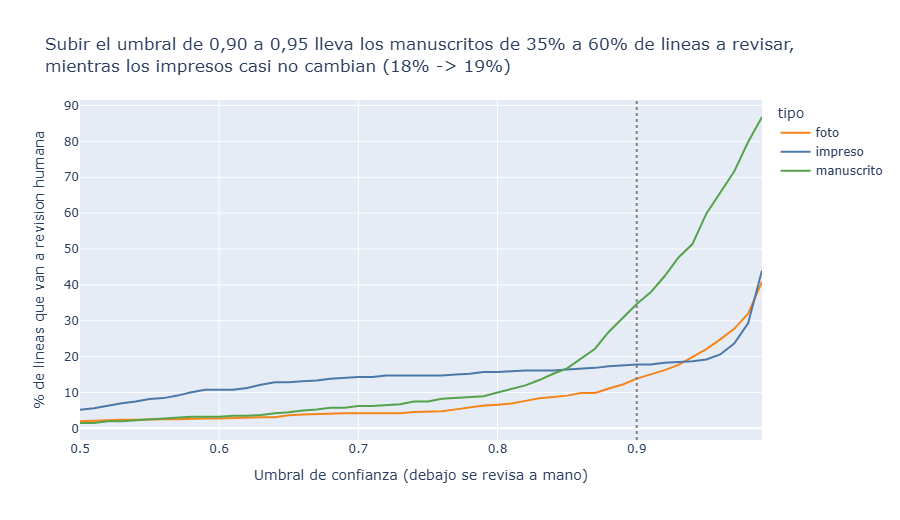

tipo,foto,impreso,manuscrito
umbral,,,
0.70,4.2,14.3,6.2
0.80,6.6,15.7,10.0
0.85,9.1,16.4,16.7
0.90,13.9,17.8,34.7
0.95,22.1,19.2,59.9
0.98,31.9,29.3,79.8


In [11]:
umbrales = np.round(np.arange(0.50, 0.991, 0.01), 2)
curva = pd.DataFrame([
    {"umbral": u, "tipo": t, "pct_a_revisar": 100 * (g["confianza"] < u).mean()}
    for u in umbrales for t, g in lineas.groupby("tipo")])
c = curva.set_index(["tipo", "umbral"])["pct_a_revisar"]

fig = px.line(curva, x="umbral", y="pct_a_revisar", color="tipo", color_discrete_map=COLORES,
              labels={"umbral": "Umbral de confianza (debajo se revisa a mano)",
                      "pct_a_revisar": "% de lineas que van a revision humana"},
              title=(f"Subir el umbral de 0,90 a 0,95 lleva los manuscritos de {c['manuscrito', 0.90]:.0f}% "
                     f"a {c['manuscrito', 0.95]:.0f}% de lineas a revisar,<br>mientras los impresos casi no cambian "
                     f"({c['impreso', 0.90]:.0f}% -> {c['impreso', 0.95]:.0f}%)"))
fig.add_vline(x=UMBRAL, line_dash="dot", line_color="gray")
fig.show()
c.unstack("tipo").loc[[0.70, 0.80, 0.85, 0.90, 0.95, 0.98]].round(1)

**Lectura de los graficos**

- El tipo de documento importa, pero lo que mas pesa es el **documento concreto**: en los impresos,
  casi toda la duda viene de la portada y la primera pagina del folleto de 1832 (tipografia antigua
  y papel manchado), no de las Memorias del BCRP.
- En los manuscritos la confianza esta "amontonada" entre 0,85 y 0,98: cualquier umbral en esa
  zona cambia mucho el trabajo de revision. En los impresos la curva es casi plana entre 0,85 y 0,95
  (las lineas o son muy buenas o muy malas); en las fotos sube de forma moderada.
- Estos graficos miden **cuanto trabajo** de revision genera cada umbral. **Cuantos errores se
  escapan** con cada umbral se medira en la Parte 2, contra la transcripcion manual.

## Validacion con los casos mas largos y mas cortos

Los extremos son donde un proceso suele fallar en silencio: un texto largo puede quedar cortado y
uno corto puede salir vacio o inventado. Se revisa:

- **Documentos**: el texto con mas y con menos caracteres. Se comprueba que `texto_ocr` sea
  exactamente la union de sus lineas en `ocr_lineas.csv` (nada se perdio al juntar).
- **Audio**: el tramo mas largo (la entrevista), y el clip mas largo y el mas corto de OpenSLR.
  Para la entrevista se mira que el ultimo segmento llegue cerca del final; para los clips, se
  compara el texto del ASR con la frase que el corpus pidio leer (`clips.csv` de OpenSLR). Esto es
  una revision a ojo, no la metrica: el WER se mide en la Parte 2 con la muestra fija.

In [12]:
docs["caracteres"] = docs["texto_ocr"].str.len()
extremos_doc = pd.concat([docs.nlargest(2, "caracteres"), docs.nsmallest(2, "caracteres")])
for _, d in extremos_doc.iterrows():
    lin = lineas[lineas["id"] == d["id"]].sort_values("linea")
    unido = " ".join(t.strip() for t in lin["texto"] if t.strip())
    print(f"\n=== {d['id']} ({d['tipo']}): {d['caracteres']} caracteres, {len(lin)} lineas, "
          f"confianza media {lin['confianza'].mean():.3f}")
    print(f"texto_ocr == union de las lineas: {unido == d['texto_ocr']}")
    print("INICIO:", d["texto_ocr"][:250])
    print("FINAL: ", d["texto_ocr"][-150:])


=== fot_Foto_regulacion_conceptos (foto): 3669 caracteres, 46 lineas, confianza media 0.973
texto_ocr == union de las lineas: True
INICIO: 5 1. Introducción La regulación económica, entendida como la intervención del Estado en los mercados,1 se construye sobre la base de los principios y modelos de la teoría microeconómica. Esta última sostiene que la competencia es la forma más eficien
FINAL:   nacional En efecto, el consumo de un ciudadano adicional no implica que otro deba del consumo de este bien mientras resida dentro de la jurisdicción.

=== fot_Foto_sintesis_reporte_marzo_2019 (foto): 3238 caracteres, 174 lineas, confianza media 0.934
texto_ocr == union de las lineas: True
INICIO: Sintesis RVA DEL PERÚ Reporte de Inflación Para este año se espera una moderación del Marzo 2019 crecimiento de la actividad económica mundial, desde 3,7 por ciento en 2018 a 3,4 por ciento, El presente Reporte de Inflación se ha elaborado con inform
FINAL:  da de capitales extemos de largo plazo del 

In [13]:
frases = pd.read_csv(RAW / "audio/es_peru/clips.csv")
frases["archivo_audio"] = frases["archivo"]
trans["palabras_por_seg"] = trans["texto_asr"].str.split().str.len() / trans["segundos"]
clips = trans[trans["id"].str.startswith("aud_pe")].merge(frases[["archivo_audio", "texto_openslr"]],
                                                       on="archivo_audio", how="left")

mas_largo = trans.loc[trans["segundos"].idxmax()]
seg = pd.read_csv(Path("datos/entrevistas") / f"{mas_largo['id']}.csv")
print(f"=== Audio mas largo: {mas_largo['id']}, {mas_largo['segundos']:.0f} s, {len(seg)} segmentos")
print(f"ultimo segmento termina en {seg['fin'].max():.1f} s; "
      f"{mas_largo['palabras_por_seg']:.2f} palabras por segundo")
print("FINAL:", mas_largo["texto_asr"][-200:])

print(f"\nPalabras por segundo en los clips: mediana {clips['palabras_por_seg'].median():.2f}, "
      f"min {clips['palabras_por_seg'].min():.2f}, max {clips['palabras_por_seg'].max():.2f}")
extremos_aud = pd.concat([clips.nlargest(2, "segundos"), clips.nsmallest(2, "segundos")])
extremos_aud[["id", "segundos", "palabras_por_seg", "texto_asr", "texto_openslr"]].round(2)

=== Audio mas largo: aud_espika_20201121_conversacion, 360 s, 227 segmentos
ultimo segmento termina en 359.7 s; 2.17 palabras por segundo
FINAL: l enotamismo para que los autobrejistas o los políticos puedan convocar a una nueva constitución? ¿Por qué no hay ahí, digamos, toda una enotamismo? ¿No hay una forma legada nuestro enotamismo? ¿Toda?

Palabras por segundo en los clips: mediana 1.63, min 0.70, max 3.11


,id,segundos,palabras_por_seg,texto_asr,texto_openslr
364,aud_pem_07508_01796320827,14.17,0.92,¿Qué me recomendarías? Una pesera de agua sala...,¿Qué me recomendarías una pecera de agua salad...
92,aud_pef_03349_01545278348,12.12,0.83,En varios países es ilegal andar en bicicleta ...,En varios países es ilegal andar en bicicleta ...
261,aud_pem_02436_01247536905,3.24,2.78,a mis hijos le gustan las cosas de acción,A mis hijos les gustan las cosas de acción.
13,aud_pef_00610_01640081214,3.33,1.80,La calle está llena de hoyos.,La calle está llena de hoyos


**Resultado de la validacion**

- **Nada se pierde al unir lineas**: en los cuatro documentos extremos, `texto_ocr` es exactamente
  la union de sus lineas.
- **El texto mas corto es una falla del OCR, el segundo no.** El letrero de Av. Sol 230
  (`Foto_nombres_empresas`) tiene ocho nombres de negocios en letras de relieve negras, y el OCR solo
  devuelve 7 caracteres: `V.SOL 3`, de la placa de la direccion. En cambio, el horario del Banco de
  la Nacion (`Foto_horario`, 104 caracteres) es corto porque el cartel es corto, y sale completo y
  correcto. Lo mismo pasa con otros documentos llenos de texto: la etiqueta de envio
  (`Foto_caja_codigos`) solo da 151 caracteres, y "Falabella" se lee "Falaela". La pagina p003 del
  folleto de 1832 es texto corrido denso y da 264 caracteres sin sentido, con todas sus lineas dudosas.
  Por eso **el largo del texto sirve como alarma solo si se compara con lo que la imagen deberia
  tener**: un documento lleno de texto que devuelve poco texto merece revision manual.
- **El documento mas largo sale completo** (la foto de *Regulacion economica*, 3669 caracteres,
  confianza media 0,97) y termina en una frase completa ("...mientras resida dentro de la jurisdiccion.").
- **Audio largo**: la conversacion de 6 min tiene 227 segmentos y el ultimo termina en 359,7 s de
  360: el ASR no corta el final.
- **Audio corto y clips largos**: los clips mas largos de OpenSLR (12-14 s) son largos por silencios,
  no por mas habla (0,8-0,9 palabras por segundo, frente a una mediana de 1,6), y el VAD los maneja
  bien: el texto coincide con la frase pedida salvo "pesera" por "pecera" y la puntuacion de la
  pregunta. El clip mas corto (3,2 s) solo pierde una "s" ("le gustan" por "les gustan").

## Exportacion

Se reescriben `documentos.csv` y `transcripciones.csv` con las columnas exactas del enunciado,
ya seudonimizados y sin los archivos descartados. `ocr_lineas.csv` solo se reescribe si la
seudonimizacion cambio alguna linea.

In [14]:
docs[COLUMNAS_DOC].to_csv("datos/documentos.csv", index=False, encoding="utf-8")
trans[COLUMNAS_AUD].to_csv("datos/transcripciones.csv", index=False, encoding="utf-8")
if (lineas["texto"] != antes_lin.loc[lineas.index]).any():
    lineas[["id", "archivo", "tipo", "linea", "texto", "confianza"]].to_csv(
        "datos/ocr_lineas.csv", index=False, encoding="utf-8")
print(f"documentos.csv: {len(docs)} filas | transcripciones.csv: {len(trans)} filas "
      f"({trans['segundos'].sum() / 60:.1f} min) | descartes.csv: {len(descartes)} filas")

documentos.csv: 28 filas | transcripciones.csv: 402 filas (50.0 min) | descartes.csv: 46 filas
